# Dev-set predictions: which training photos does the model get right?

We cannot score the Kaggle test photos ourselves, so we use the 66 labelled training photos as a **dev test**:
every photo is predicted by a model that did **not** see it during training (5-fold cross-validation, repeated 10 times;
each photo's 10 out-of-fold probabilities are averaged).

The model is the one behind the current `submission.csv` (`python train.py --modes aug ...`): the average of three
image-only classifiers trained on the original + 20 augmented views of each photo. No text encoder, no language model.

Photos are grouped by the **true** chore, then by whether the prediction was correct.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold

from train import CLASSES, ROOT, fit_predict, load, train, y

MEMBERS = [  # (backbone, view mode, classifier), the "best run per backbone" ensemble
    ("dinov2_l", "aug", "RBF SVM C=3"),
    ("siglip_so400m", "aug", "logreg C=1"),
    ("eva02_l", "aug", "extra trees"),
]
REPEATS = 10
SHORT = {c: c.replace("Washing Dishes", "Dishes").replace("Taking Out Trash", "Trash") for c in CLASSES}

## 1. Out-of-fold predictions

In [2]:
F = {b: load(b) for b in {m[0] for m in MEMBERS}}
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=REPEATS, random_state=0).split(y, y))

proba = np.zeros((len(y), 4))
for b, mode, clf in MEMBERS:
    t0 = time.time()
    p = np.zeros((len(y), 4))
    for tr, va in splits:
        p[va] += fit_predict(F, b, mode, clf, tr, "tr", va)
    p /= REPEATS
    proba += p / len(MEMBERS)
    print(f"[{b} | {mode} | {clf}] dev macro F1 {f1_score(y, p.argmax(1), average='macro'):.3f}  ({time.time() - t0:.0f}s)")

pred = proba.argmax(1)
dev = train.assign(true=[SHORT[CLASSES[k]] for k in y], pred=[SHORT[CLASSES[k]] for k in pred],
                   conf=proba.max(1), correct=pred == y, chore=np.where(y < 2, "Dishes", "Trash"))
print(f"\nEnsemble dev macro F1 {f1_score(y, pred, average='macro'):.3f}, "
      f"accuracy {dev.correct.mean():.3f} ({dev.correct.sum()}/{len(dev)})")

[dinov2_l | aug | RBF SVM C=3] dev macro F1 0.844  (7s)


[siglip_so400m | aug | logreg C=1] dev macro F1 0.844  (1s)


[eva02_l | aug | extra trees] dev macro F1 0.776  (13s)

Ensemble dev macro F1 0.859, accuracy 0.864 (57/66)


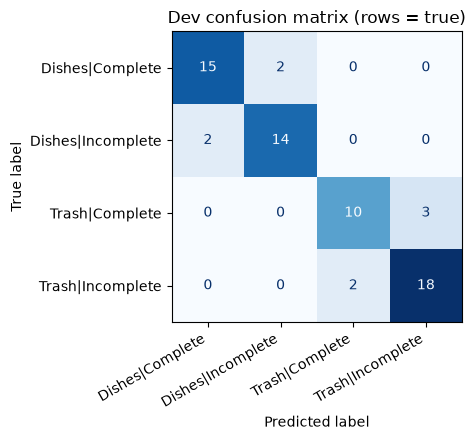

,wrong,correct
chore,,
Dishes,4,29
Trash,5,28


In [3]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=[SHORT[c] for c in CLASSES]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Dev confusion matrix (rows = true)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
dev.groupby(["chore", "correct"]).size().unstack().rename(columns={True: "correct", False: "wrong"}).rename_axis(columns=None)

## 2. Photos, two per row

Title: photo id, true label, predicted label and the model's confidence. Green = correct, red = wrong.

In [4]:
def show(rows, title):
    print(f"{title}: {len(rows)} photos")
    if rows.empty:
        return
    n = int(np.ceil(len(rows) / 2))
    fig, axes = plt.subplots(n, 2, figsize=(11, 5.2 * n), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, r in zip(axes.ravel(), rows.itertuples()):
        im = ImageOps.exif_transpose(Image.open(ROOT / "data" / "images" / r.image_file)).convert("RGB")
        im.thumbnail((450, 450))
        ax.imshow(im)
        ax.set_title(f"#{r.id}  true: {r.true}\npred: {r.pred} ({r.conf:.0%})", fontsize=12,
                     color="green" if r.correct else "red")
    fig.suptitle(title, fontsize=15, y=1.0)
    plt.tight_layout(); plt.show()

### 2.1 Dishes: correct

Dishes - correct in dev test: 29 photos


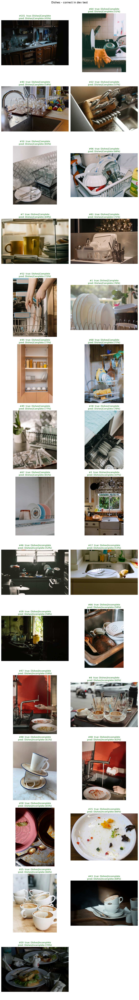

In [5]:
show(dev[(dev.chore == "Dishes") & dev.correct].sort_values(["true", "conf"]), "Dishes - correct in dev test")

### 2.2 Dishes: wrong

Dishes - wrong in dev test: 4 photos


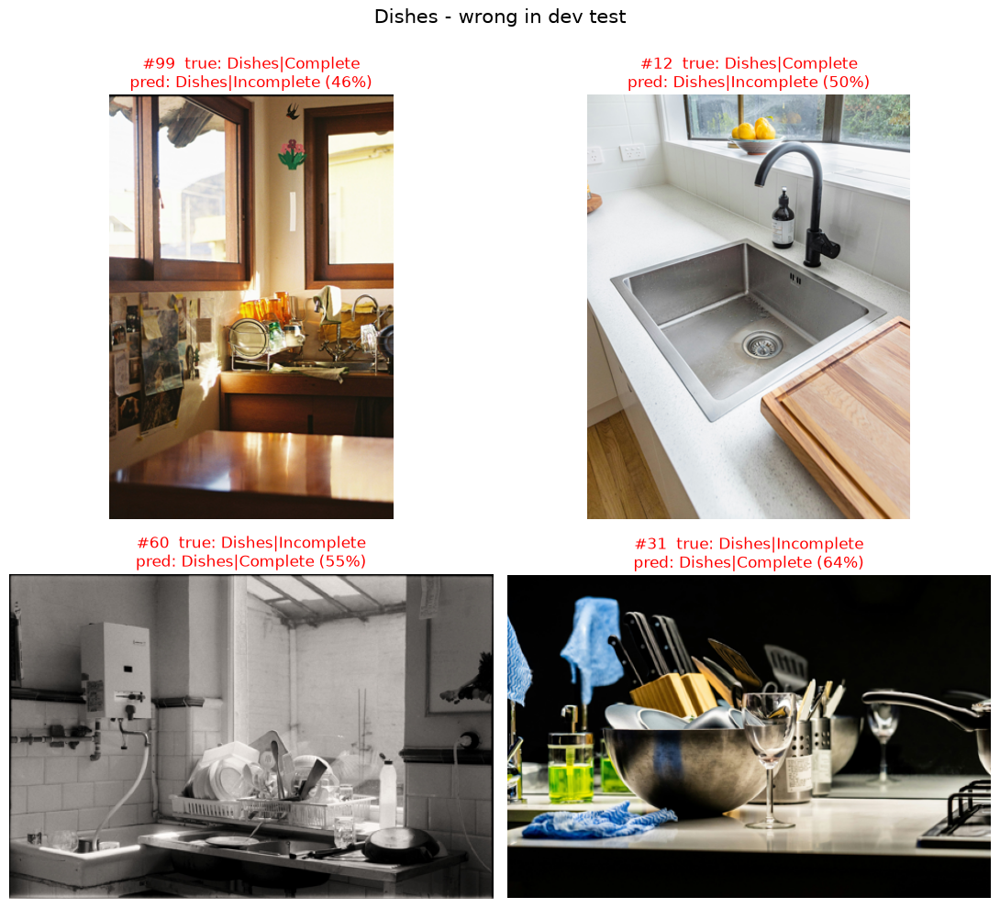

In [6]:
show(dev[(dev.chore == "Dishes") & ~dev.correct].sort_values(["true", "conf"]), "Dishes - wrong in dev test")

### 2.3 Trash: correct

Trash - correct in dev test: 28 photos


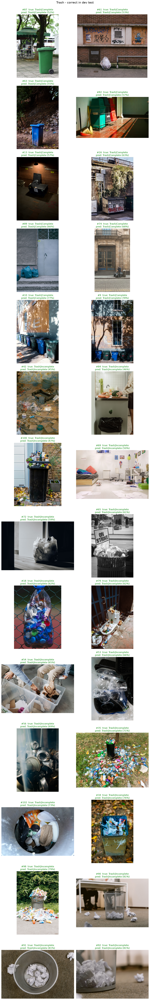

In [7]:
show(dev[(dev.chore == "Trash") & dev.correct].sort_values(["true", "conf"]), "Trash - correct in dev test")

### 2.4 Trash: wrong

Trash - wrong in dev test: 5 photos


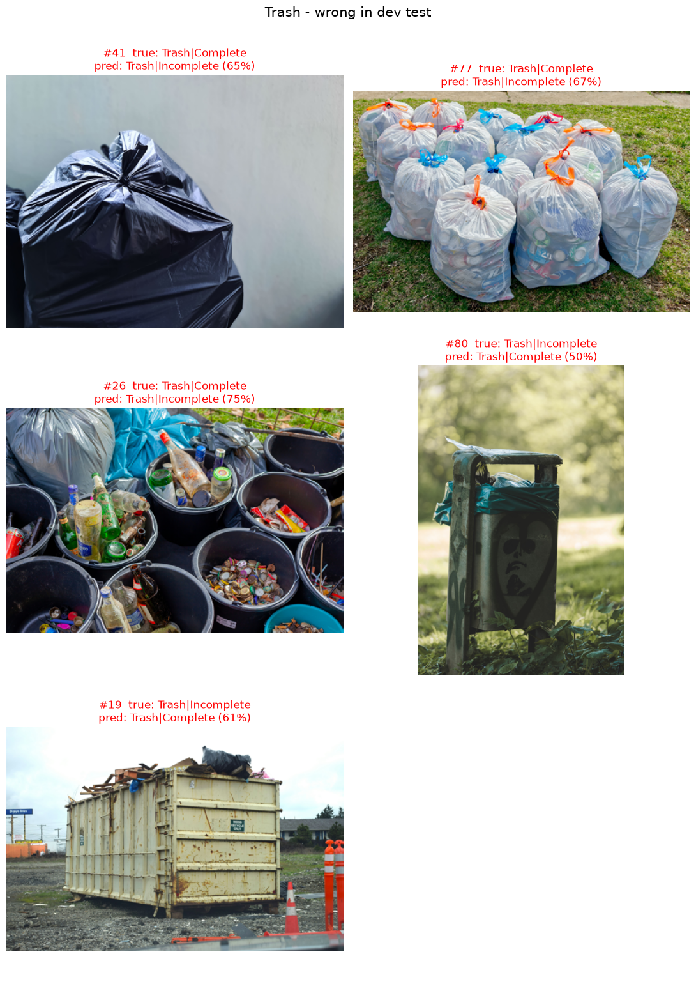

In [8]:
show(dev[(dev.chore == "Trash") & ~dev.correct].sort_values(["true", "conf"]), "Trash - wrong in dev test")